# Gradient Boosting

# Load Data

In [2]:
import sys
from pathlib import Path

project_root = Path.cwd()
while not (project_root / "src").is_dir():
    if project_root == project_root.parent:
        raise FileNotFoundError("Could not locate the project root")
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data.load_data import load_nsl_kdd

train,test = load_nsl_kdd()
train.head()



True


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class,y
0,0.0,tcp,ftp_data,SF,491.0,0.0,0,0.0,0.0,0.0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,0
1,0.0,udp,other,SF,146.0,0.0,0,0.0,0.0,0.0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,0
2,0.0,tcp,private,S0,0.0,0.0,0,0.0,0.0,0.0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly,1
3,0.0,tcp,http,SF,232.0,8153.0,0,0.0,0.0,0.0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,0
4,0.0,tcp,http,SF,199.0,420.0,0,0.0,0.0,0.0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,0


In [4]:
train.keys()

Index(['duration', 'protocol_type', 'service', 'flag', 'src_bytes',
       'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
       'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
       'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
       'num_access_files', 'num_outbound_cmds', 'is_host_login',
       'is_guest_login', 'count', 'srv_count', 'serror_rate',
       'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
       'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
       'dst_host_srv_count', 'dst_host_same_srv_rate',
       'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
       'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
       'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
       'dst_host_srv_rerror_rate', 'class', 'y'],
      dtype='str')

## Preprocessing Data

In [8]:
from src.data.preprocess import prep

# Preprocess the training data
target = train["y"]
preprocessor = prep()
train_preprocessed = preprocessor.fit_transform(train)
#print(target)
print(train_preprocessed)

[[-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 ...
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]
 [-0.09129752 -0.02984092 -0.07005841 ...  0.          1.
   0.        ]]


In [1]:
import xgboost as xgb
print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


## Train Model

In [ ]:
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split

#Splitting data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(train_preprocessed, target, test_size=0.2, random_state=42, stratify=target)

# Encode string labels to integers (a requirement for XGBoost for classification)
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.fit_transform(y_test)


#Initialize the XGBoost classifier
# It uses very similar parameters to scikit-learn's GradientBoostingClassifier, (but with some differences, can adjust based on needs)
xgb_model = xgb.XGBClassifier(
    #hyperparameters for the XGBoost model; Question why are these specific hyperparameters chosen? (Test different values to see their impactz)
    objective='binary:logistic',  # For binary classification
    n_estimators=100,  # Number of boosting rounds
    learning_rate=0.1,  # Step size shrinkage
    max_depth=3,  # Maximum depth of a tree
    subsample=0.8,  # Subsample ratio of the training instance
    colsample_bytree=0.8,  # Subsample ratio of columns when constructing each tree
    random_state=42,  # For reproducibility
    eval_metric='logloss'  # Evaluation metric for binary classification
)

#Train the model
print("Training the XGBoost model...")
xgb_model.fit(X_train, y_train_encoded)

#Making predictions on the test set
print("Making predictions...")
predictions = xgb_model.predict(X_test)

#Evaluating the model's performance/ after calibration
#print("Evaluating the model...")
#accuracy= accuracy_score(y_test_encoded, predictions)
#print(f"XGBoost Model Accuracy: {accuracy * 100:.2f}%\n")


Training the XGBoost model...
Making predictions...


## Visualizing Model

Matplotlib is building the font cache; this may take a moment.


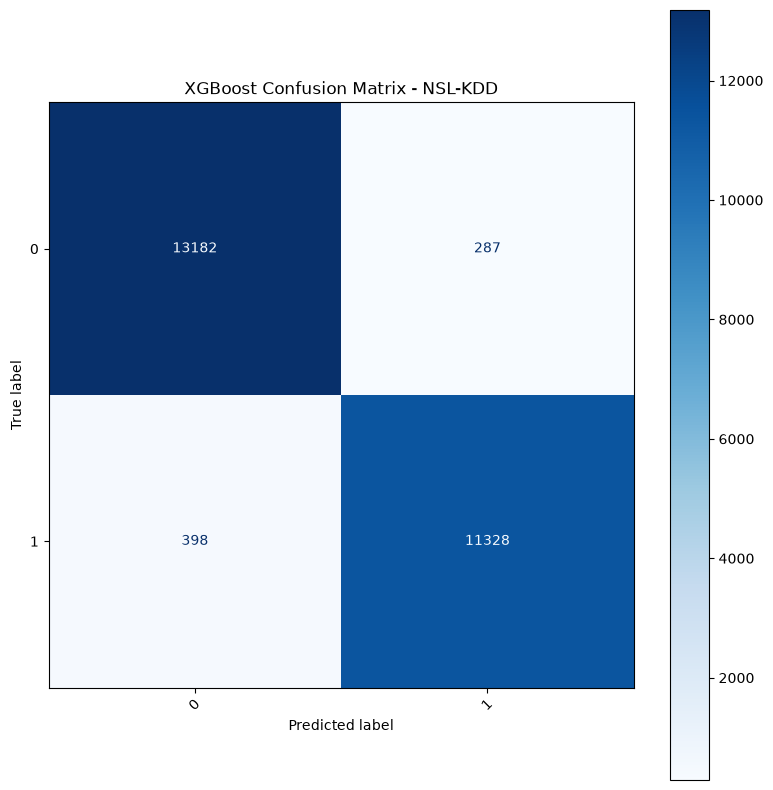

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay 

#Create a figure and axis for the CMD
fig, ax = plt.subplots(figsize=(8,8))

#Generate the confusion matrix plot from the trained XGBoost estimator
ConfusionMatrixDisplay.from_estimator(
    xgb_model,
    X_test,
    y_test_encoded,
    display_labels=label_encoder.classes_,
    cmap=plt.cm.Blues,
    ax=ax,
    xticks_rotation=45
)

plt.title("XGBoost Confusion Matrix - NSL-KDD")
plt.tight_layout()
plt.show()
